# RQ2 — Where the relationships occur and what diverges

Reproduces the subsections *Where the relationships occur* and *What tends to diverge*:

| Result in the paper | Where |
|---|---|
| Evidence items per relationship and per RQ1 category (figure) | section 1 |
| Repository-level view: redundancy and conflict rate per category | section 2 |
| Table of conflict types | section 3 |

Inputs:
- `data/rq02/evidence/rq02_evidence.csv`: relationships marked per repository and the recorded evidence;
- `data/rq02/evidence/rq02_evidence_items.csv`: the evidence split into items, each with an RQ1
  category and the status of the excerpt location in the files (`OK`, `PARCIAL` = partial,
  `NAO_LOCALIZADO` = not found, `DESCARTADO` = discarded);
- `data/rq01/classifier/rq01_classification_run_1.csv`: categories of each file (section 2).

Rule: only `OK` and `PARCIAL` items of repositories in which the relationship is marked are counted.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "data" / "collection").exists():
    ROOT = ROOT.parent

REPOS = ROOT / "data/rq02/evidence/rq02_evidence.csv"
ITEMS = ROOT / "data/rq02/evidence/rq02_evidence_items.csv"
RQ01 = ROOT / "data/rq01/classifier/rq01_classification_run_1.csv"
OUT = ROOT / "results/rq02"
OUT.mkdir(parents=True, exist_ok=True)

# Order of the RQ1 prevalence table
CATEGORIES = ["test_instructions", "code_conventions", "run_and_build", "ai_rules", "project_overview",
              "doc_metadata", "project_structure", "contribution_guidelines", "system_design",
              "troubleshooting", "security", "deployment_&_infrastructure", "performance_&_resource_management"]
RELATIONSHIPS = ["conflitantes", "redundantes", "complementares"]
NAME_EN = {"conflitantes": "conflicting", "redundantes": "redundant", "complementares": "complementary"}


def repo_key(value):
    m = re.search(r"github\.com/([^/\s]+)/([^/\s]+)", str(value))
    return (f"{m.group(1)}/{m.group(2)}" if m else str(value).strip()).lower()


repos = pd.read_csv(REPOS)
repos["key"] = repos["repo"].map(repo_key)
marked = repos.set_index("key")[RELATIONSHIPS]

items = pd.read_csv(ITEMS)
items["key"] = items["repo"].map(repo_key)
print("Items by status:", items["status"].value_counts().to_dict())
valid = items[items["status"].isin(["OK", "PARCIAL"])]
valid = valid[[marked.loc[k, r] == 1 for k, r in zip(valid["key"], valid["relacao"])]].copy()
print(f"Valid items: {len(valid)}", {NAME_EN[r]: n for r, n in valid["relacao"].value_counts().reindex(RELATIONSHIPS).items()})

Items by status: {'OK': 212, 'PARCIAL': 36, 'NAO_LOCALIZADO': 8, 'DESCARTADO': 1}
Valid items: 248 {'conflicting': 16, 'redundant': 99, 'complementary': 133}


## 1. Items per relationship and category

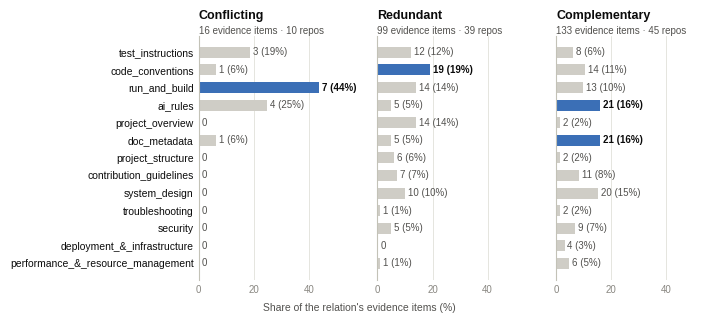

relacao,conflicting,redundant,complementary
categoria_rq01,,,
test_instructions,3,12,8
code_conventions,1,19,14
run_and_build,7,14,13
ai_rules,4,5,21
project_overview,0,14,2
doc_metadata,1,5,21
project_structure,0,6,2
contribution_guidelines,0,7,11
system_design,0,10,20


In [2]:
counts = (valid.groupby(["relacao", "categoria_rq01"]).size().unstack(fill_value=0)
          .reindex(index=RELATIONSHIPS, columns=CATEGORIES, fill_value=0))
n_repos = valid.groupby("relacao")["key"].nunique().reindex(RELATIONSHIPS)
counts.T.rename(columns=NAME_EN).to_csv(OUT / "items_by_category_and_relationship.csv")

TITLE = {"conflitantes": "Conflicting", "redundantes": "Redundant", "complementares": "Complementary"}
HIGHLIGHT, CONTEXT, INK, INK2, MUTED, GRID = "#3b6fb6", "#cfcdc6", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Helvetica", "Arial", "Liberation Sans", "DejaVu Sans"],
                     "font.size": 8, "svg.fonttype": "none", "pdf.fonttype": 42})
fig, axes = plt.subplots(1, 3, figsize=(7.16, 3.3), sharey=True)
y = range(len(CATEGORIES))
for ax, rel in zip(axes, RELATIONSHIPS):
    k = counts.loc[rel]
    n = int(k.sum())
    pct = 100 * k / n
    top = pct.max()
    ax.barh(list(y), pct.values, height=0.62, color=[HIGHLIGHT if p == top else CONTEXT for p in pct], zorder=2)
    for i, (c, p) in enumerate(zip(k.values, pct.values)):
        ax.text(p + 1.0, i, f"{c} ({p:.0f}%)" if c else "0", va="center", ha="left", fontsize=7,
                color=INK if p == top else INK2, fontweight="bold" if p == top else "normal")
    ax.set_xlim(0, 56)
    ax.set_xticks([0, 20, 40])
    ax.tick_params(axis="x", colors=MUTED, labelsize=7, length=0)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color=GRID, linewidth=0.6, zorder=0)
    for side in ["top", "right", "bottom"]:
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color("#c3c2b7")
    ax.set_title(f"{TITLE[rel]}\n", loc="left", fontsize=9, fontweight="bold", color=INK, pad=2)
    ax.text(0, 1.0, f"{n} evidence items · {int(n_repos[rel])} repos", transform=ax.transAxes,
            fontsize=7, color=INK2, va="bottom", ha="left")
axes[0].set_yticks(list(y))
axes[0].set_yticklabels(CATEGORIES, fontsize=7.5, color=INK)
axes[0].invert_yaxis()
fig.supxlabel("Share of the relation's evidence items (%)", fontsize=7.5, color=INK2, y=0.02)
fig.subplots_adjust(left=0.275, right=0.99, top=0.86, bottom=0.12, wspace=0.16)
for ext in ["svg", "pdf"]:
    fig.savefig(OUT / f"category-by-relationship.{ext}", facecolor="white")
plt.show()
counts.T.rename(columns=NAME_EN)

## 2. Repository-level view

Denominator: repositories of the sample in which the category appears in two or more files,
according to the RQ1 classification. Numerator: of these, how many have an item of that
relationship in that category.

In [3]:
rq01 = pd.read_csv(RQ01)
rq01["key"] = rq01["repo"].str.lower()
sharing = {c: set() for c in CATEGORIES}
for _, row in repos.iterrows():
    files = [x.strip() for x in str(row["arquivos_para_analisar"]).split(";")]
    sub = rq01[(rq01["key"] == row["key"]) & rq01["arquivo_analisado"].isin(files)].drop_duplicates("arquivo_analisado")
    for c in CATEGORIES:
        if (pd.to_numeric(sub[c], errors="coerce") == 1).sum() >= 2:
            sharing[c].add(row["key"])

rows = []
for c in CATEGORIES:
    base = sharing[c]
    row = {"category": c, "repos_in_2plus_files": len(base)}
    for rel in ["redundantes", "conflitantes"]:
        with_rel = set(valid.loc[(valid["relacao"] == rel) & (valid["categoria_rq01"] == c), "key"]) & base
        row[NAME_EN[rel]] = len(with_rel)
        row[f"pct_{NAME_EN[rel]}"] = round(100 * len(with_rel) / len(base)) if base else None
    rows.append(row)
by_repo = pd.DataFrame(rows).sort_values("repos_in_2plus_files", ascending=False).reset_index(drop=True)
by_repo.to_csv(OUT / "relationships_by_category_repository.csv", index=False)
by_repo

,category,repos_in_2plus_files,redundant,pct_redundant,conflicting,pct_conflicting
0,code_conventions,26,11,42,0,0
1,ai_rules,25,4,16,3,12
2,run_and_build,24,11,46,5,21
3,test_instructions,21,8,38,1,5
4,contribution_guidelines,19,3,16,0,0
5,project_overview,18,11,61,0,0
6,doc_metadata,16,4,25,1,6
7,project_structure,16,4,25,0,0
8,system_design,10,6,60,0,0
9,security,5,2,40,0,0


## 3. Conflict types

The type was assigned to each conflicting item from the quoted excerpts.

In [4]:
TYPE = {
    ("apache/shardingsphere", 1): "Opposite directive", ("apache/shardingsphere", 2): "Opposite directive",
    ("apache/shardingsphere", 3): "Opposite directive", ("module-federation/core", 1): "Opposite directive",
    ("module-federation/core", 2): "Opposite directive",
    ("dotcms/core", 1): "Divergent version", ("slick/slick", 1): "Divergent version",
    ("slick/slick", 2): "Divergent version", ("slick/slick", 3): "Divergent version",
    ("heroui-inc/heroui", 1): "Divergent version",
    ("meshtastic/firmware", 1): "Divergent fact or reference", ("meshtastic/firmware", 2): "Divergent fact or reference",
    ("tuist/tuist", 1): "Divergent command syntax", ("humanizr/humanizer", 1): "Divergent command syntax",
    ("prettier/prettier-vscode", 1): "Divergent artifact name",
    ("wled/wled", 1): "Divergent operational value",
}
conflicts = valid[valid["relacao"] == "conflitantes"].copy()
conflicts["type"] = [TYPE[(k, n)] for k, n in zip(conflicts["key"], conflicts["item_n"])]
conflicts[["key", "item_n", "type", "categoria_rq01", "arquivo_a", "trecho_a", "arquivo_b", "trecho_b"]] \
    .to_csv(OUT / "conflicting_items.csv", index=False)
types = (conflicts.groupby("type").agg(items=("key", "size"), repos=("key", "nunique"))
         .sort_values(["items", "repos"], ascending=False))
types.to_csv(OUT / "conflict_types.csv")
types

,items,repos
type,,
Divergent version,5,3
Opposite directive,5,2
Divergent command syntax,2,2
Divergent fact or reference,2,1
Divergent artifact name,1,1
Divergent operational value,1,1
